
>**CONFIGURACIÓN Y CARGA DE DATOS**



In [1]:
# IMPORTS Y CONFIGURACIÓN DE RUTAS DE PROYECTO
from pathlib import Path
import pandas as pd
import json
import numpy as np
import hashlib
import pickle
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
import matplotlib.pyplot as plt
import joblib
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, roc_curve
)

# IMPORTS DESDE MÓDULO DE CONFIGURACIÓN
from Configuracion import CARGADOS, PROCESADOS, CSV_GENERADOS, IMPLEMENTACION_GOBERNANZA, ANALITICOS_PARQUET, ANALITICOS_RESULTADOS, MODELOS_ML
from Configuracion import RECURSOS

# CREACIÓN DE CARPETAS SEGMENTADAS
modelo_carpetas = [
    CARGADOS, PROCESADOS, CSV_GENERADOS,
    IMPLEMENTACION_GOBERNANZA, ANALITICOS_PARQUET, ANALITICOS_RESULTADOS,
    RECURSOS, MODELOS_ML
]

for modelo_carpeta in modelo_carpetas:
    modelo_carpeta.mkdir(parents=True, exist_ok=True)

print("Estructura de carpetas creada correctamente ------")

# LECTURA DEL ARCHIVO .PKL USANDO LA RUTA CONFIGURADA
RUTA_PKL =  MODELOS_ML / "datos_split_guia8.pkl"

with open(RUTA_PKL, "rb") as f:
    datos = pickle.load(f)

X_train = datos["X_train"]
X_val   = datos["X_val"]
X_test  = datos["X_test"]
y_train = datos["y_train"]
y_val   = datos["y_val"]
y_test  = datos["y_test"]

COLS_NUMERICAS   = datos["COLS_NUMERICAS"]
COLS_CATEGORICAS = datos["COLS_CATEGORICAS"]
TARGET           = datos["TARGET"]

print(f"¡Datos cargados con éxito desde: {RUTA_PKL}!")
print(f"Registros de entrenamiento: {len(X_train)} | Registros de prueba: {len(X_test)}")



Estructura de carpetas creada correctamente ------
¡Datos cargados con éxito desde: ..\Datos\Modelos\datos_split_guia8.pkl!
Registros de entrenamiento: 396267 | Registros de prueba: 84915



>**ENTRENAMIENTO Y AJUSTE DE MODELOS**



In [2]:
#Bloque 2, Entrenamiento de modelo candidato Regresión Logística balanceada

# Preprocesador para estandarizar las numéricas y aplicar One-Hot a las categóricas
preprocesador = ColumnTransformer([
    ("num", StandardScaler(), COLS_NUMERICAS),
    ("cat", OneHotEncoder(handle_unknown="ignore"), COLS_CATEGORICAS),
])

modelo = Pipeline([
    ("prep", preprocesador),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)),
])

modelo.fit(X_train, y_train)

print("Modelo entrenado")
print("Iteraciones usadas:", modelo.named_steps["clf"].n_iter_[0])

Modelo entrenado
Iteraciones usadas: 179


In [3]:
#Bloque 3, comparación de pesos en validación

modelo_sin_peso = Pipeline([
    ("prep", clone(preprocesador)),
    ("clf", LogisticRegression(max_iter=1000, random_state=42)),
])
modelo_sin_peso.fit(X_train, y_train)

def evaluar(m, X, y):
    pred = m.predict(X)
    prob = m.predict_proba(X)[:, 1]
    return {
        "Accuracy": accuracy_score(y, pred),
        "Precision": precision_score(y, pred),
        "Recall": recall_score(y, pred),
        "F1-Score": f1_score(y, pred),
        "ROC-AUC": roc_auc_score(y, prob),
    }

comparacion = pd.DataFrame({
    "balanced": evaluar(modelo, X_val, y_val),
    "sin_peso": evaluar(modelo_sin_peso, X_val, y_val),
}).round(4)

print(comparacion)

           balanced  sin_peso
Accuracy     0.8514    0.9245
Precision    0.5741    0.8832
Recall       0.9558    0.7115
F1-Score     0.7174    0.7881
ROC-AUC      0.9569    0.9558


In [4]:
#Bloque 4, Entrenamiento de modelo Random Forest

# Creamos el pipeline con el Random Forest
modelo_rf = Pipeline([
    ("prep", preprocesador),
    ("clf", RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )),
])

# Entrenamos con los datos de entrenamiento que se cargaron del archivo
modelo_rf.fit(X_train, y_train)
print("¡Modelo Random Forest entrenado exitosamente!")

¡Modelo Random Forest entrenado exitosamente!



> ## Evaluación inicial con conjunto de prueba

>**MODELO DE REGRESIÓN LOGÍSTICA**

In [5]:
# Generar predicciones de ataque sobre el conjunto de prueba
y_pred = modelo.predict(X_test)
y_prob = modelo.predict_proba(X_test)[:, 1]

#Calcular las métricas de evaluación de la Regresión Logística
metricas = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1-Score": f1_score(y_test, y_pred),
    "ROC-AUC": roc_auc_score(y_test, y_prob),
}

print("Métricas en el conjunto de prueba:")
for nombre, valor in metricas.items():
    print(f"{nombre}: {valor:.4f}")

#Desglosar aciertos y errores mediante la matriz de confusión
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print("\nMatriz de confusión:")
print(f"TN = {tn} | FP = {fp}")
print(f"FN = {fn} | TP = {tp}")

Métricas en el conjunto de prueba:
Accuracy: 0.8510
Precision: 0.5732
Recall: 0.9571
F1-Score: 0.7170
ROC-AUC: 0.9573

Matriz de confusión:
TN = 56229 | FP = 11936
FN = 718 | TP = 16032


>**MODELO Random Forest**

In [6]:

# Generar predicciones sobre el conjunto de prueba
y_pred_rf = modelo_rf.predict(X_test)
y_prob_rf = modelo_rf.predict_proba(X_test)[:, 1]

# Calcular métricas
metricas_rf = {
    "Accuracy": accuracy_score(y_test, y_pred_rf),
    "Precision": precision_score(y_test, y_pred_rf),
    "Recall": recall_score(y_test, y_pred_rf),
    "F1-Score": f1_score(y_test, y_pred_rf),
    "ROC-AUC": roc_auc_score(y_test, y_prob_rf),
}

print("Métricas de tu Modelo Adicional (Random Forest):")
for nombre, valor in metricas_rf.items():
    print(f"{nombre}: {valor:.4f}")

#Desglosar aciertos y errores mediante la matriz de confusión
tn, fp, fn, tp = confusion_matrix(y_test, y_pred_rf).ravel()
print(f"\nMatriz de confusión -> TN = {tn} | FP = {fp} | FN = {fn} | TP = {tp}")

Métricas de tu Modelo Adicional (Random Forest):
Accuracy: 0.9971
Precision: 0.9886
Recall: 0.9967
F1-Score: 0.9926
ROC-AUC: 0.9998

Matriz de confusión -> TN = 67972 | FP = 193 | FN = 55 | TP = 16695



>**BASELINE COMO MODELO DE REFRENCIA**



In [7]:
# Entrenar el clasificador basico usando el mismo preprocesador
Dummy = Pipeline([
    ("prep", clone(preprocesador)),
    ("clf", DummyClassifier(strategy="most_frequent")),
])

Dummy.fit(X_train, y_train)

# Evaluación de referencia en el conjunto de prueba
y_pred_dummy = Dummy.predict(X_test)
print("Línea base entrenada exitosamente.")
print(f"Accuracy Dummy (test): {accuracy_score(y_test, y_pred_dummy):.4f}")
print(f"F1-Score Dummy (test): {f1_score(y_test, y_pred_dummy, zero_division=0):.4f}")

Línea base entrenada exitosamente.
Accuracy Dummy (test): 0.8027
F1-Score Dummy (test): 0.0000



>**REVISION DE SOBREAJUSTE**

In [8]:
# Calcular el F1-Score de los tres modelos en entrenamiento y prueba
modelos_evaluar = {
    "Dummy (Línea base)": Dummy,
    "Regresión Logística (modelo)": modelo,
    "Random Forest (modelo_rf)": modelo_rf
}

resultados_brecha = []
for nombre, est in modelos_evaluar.items():
    pred_train = est.predict(X_train)
    pred_test = est.predict(X_test)
    
    f1_tr = f1_score(y_train, pred_train, zero_division=0)
    f1_te = f1_score(y_test, pred_test, zero_division=0)
    
    resultados_brecha.append({
        "Modelo": nombre,
        "F1_train (Estudio)": f1_tr,
        "F1_test (Examen)": f1_te,
        "Brecha_F1 (Train - Test)": f1_tr - f1_te
    })

df_sobreajuste = pd.DataFrame(resultados_brecha).round(4)
print("--- COMPARATIVA ESTUDIO VS. EXAMEN (DIAGNÓSTICO DE SOBREAJUSTE) ---")
print(df_sobreajuste.to_string(index=False))

--- COMPARATIVA ESTUDIO VS. EXAMEN (DIAGNÓSTICO DE SOBREAJUSTE) ---
                      Modelo  F1_train (Estudio)  F1_test (Examen)  Brecha_F1 (Train - Test)
          Dummy (Línea base)              0.0000            0.0000                    0.0000
Regresión Logística (modelo)              0.7163            0.7170                   -0.0008
   Random Forest (modelo_rf)              0.9956            0.9926                    0.0030



>**RANKING DE VARIABLES DEL RANDOM FOREST**



In [9]:
# Extraer la importancia de las características del modelo_rf y cruzarlas con el preprocesador
nombres_columnas = modelo_rf.named_steps["prep"].get_feature_names_out()
importancias = modelo_rf.named_steps["clf"].feature_importances_

ranking_variables = (
    pd.DataFrame({
        "Variable": nombres_columnas,
        "Importancia": importancias
    })
    .assign(Variable=lambda d: d["Variable"].str.replace("num__", "").str.replace("cat__", ""))
    .sort_values("Importancia", ascending=False)
    .reset_index(drop=True)
)

print("--- TOP 10 VARIABLES CON MAYOR PESO PARA DETECTAR ATAQUES ---")
print(ranking_variables.head(10).round(4).to_string(index=False))

--- TOP 10 VARIABLES CON MAYOR PESO PARA DETECTAR ATAQUES ---
                   Variable  Importancia
      total_flags_activadas       0.1198
     init_win_bytes_forward       0.1161
    init_win_bytes_backward       0.1010
          packet_length_std       0.0762
total_length_of_fwd_packets       0.0686
         packet_length_mean       0.0647
     bwd_packet_length_mean       0.0595
total_length_of_bwd_packets       0.0577
     fwd_packet_length_mean       0.0550
        ratio_fwd_bwd_bytes       0.0532


>**VALIDACION CRUZADA**

In [10]:
# Configuracion de particiones 
particiones = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

#Modelos a relacionar
modelos_validacion = {
    "Dummy (Línea base)": Dummy,
    "Regresión Logística (modelo)": modelo,
    "Random Forest (modelo_rf)": modelo_rf
}

resultados_validacion = []

#Recorrido de modelos
for nombre, est in modelos_validacion.items():
    
    #Uso decopia limpia sin entrenar para evitar fuga de datos entre iteraciones.
    scores_f1 = cross_val_score(clone(est), X_train, y_train, cv=particiones, scoring="f1", n_jobs=-1) #desviación estándar
    scores_recall = cross_val_score(clone(est), X_train, y_train, cv=particiones, scoring="recall", n_jobs=-1) #Sensibilidad del modelo
    
    #Agregacion de rendimeitno y desviacion
    resultados_validacion.append({
        "Modelo": nombre,
        "F1_CV_Media": scores_f1.mean(),
        "F1_CV_DesvStd": scores_f1.std(),
        "Recall_CV_Media": scores_recall.mean(),
        "Estable (Desv < 0.02)": scores_f1.std() < 0.02
    })

df_resultados_validacion = pd.DataFrame(resultados_validacion).round(4)
print("--- VALIDACIÓN CRUZADA CON USO DE 5 FOLDS) ---")
print(df_resultados_validacion.to_string(index=False))


--- VALIDACIÓN CRUZADA CON USO DE 5 FOLDS) ---
                      Modelo  F1_CV_Media  F1_CV_DesvStd  Recall_CV_Media  Estable (Desv < 0.02)
          Dummy (Línea base)       0.0000         0.0000           0.0000                   True
Regresión Logística (modelo)       0.7146         0.0026           0.9570                   True
   Random Forest (modelo_rf)       0.9930         0.0007           0.9961                   True


>**CREACION DE TABLA MAESTRA**

In [11]:
# Metricas de prueba para modelo dummy
metricas_dummy = {
    "Accuracy": accuracy_score(y_test, y_pred_dummy),
    "Precision": precision_score(y_test, y_pred_dummy, zero_division=0),
    "Recall": recall_score(y_test, y_pred_dummy, zero_division=0),
    "F1-Score": f1_score(y_test, y_pred_dummy, zero_division=0),
    "ROC-AUC": 0.5000
}

#modelos incluidos con sus metricas
df_metricas_test = pd.DataFrame([
    {"Modelo": "Dummy (Línea base)", **metricas_dummy},
    {"Modelo": "Regresión Logística (modelo)", **metricas},
    {"Modelo": "Random Forest (modelo_rf)", **metricas_rf},
])

# Conjunto de revisiones para modelos: Metricas de prueba + sobreajuste + validacion cruzada
tabla_decision = (
    df_metricas_test
    .merge(df_sobreajuste[["Modelo", "F1_train (Estudio)", "Brecha_F1 (Train - Test)"]], on="Modelo")
    .merge(df_resultados_validacion[["Modelo", "F1_CV_Media", "F1_CV_DesvStd", "Recall_CV_Media"]], on="Modelo")
)

# Reverificacion de parametros minimos para seleccionar modelo candidato
f1_baseline = tabla_decision.loc[tabla_decision["Modelo"] == "Dummy (Línea base)", "F1-Score"].values[0]
tabla_decision["Supera_Baseline"] = tabla_decision["F1-Score"] > f1_baseline
tabla_decision["Sin_Overfitting"] = tabla_decision["Brecha_F1 (Train - Test)"] < 0.05
tabla_decision["Es_Estable"]      = tabla_decision["F1_CV_DesvStd"] < 0.02
tabla_decision["Alto_Recall"] = tabla_decision["Recall"] >= 0.95
tabla_decision = tabla_decision.round(4)

print("TABLA MAESTRA PARA ELECCION DE MODELO CANDIDATO\n")
print(tabla_decision.to_string(index=False))

# Guardado de archivos para documentacion 
tabla_decision.to_csv(MODELOS_ML / "comparacion_modelos_guia09.csv", index=False, encoding="utf-8-sig")
ranking_variables.to_csv(MODELOS_ML / "ranking_variables_guia09.csv", index=False, encoding="utf-8-sig")
df_resultados_validacion.to_csv(MODELOS_ML / "validacion_cruzada_guia09.csv", index=False, encoding="utf-8-sig")


TABLA MAESTRA PARA ELECCION DE MODELO CANDIDATO

                      Modelo  Accuracy  Precision  Recall  F1-Score  ROC-AUC  F1_train (Estudio)  Brecha_F1 (Train - Test)  F1_CV_Media  F1_CV_DesvStd  Recall_CV_Media  Supera_Baseline  Sin_Overfitting  Es_Estable  Alto_Recall
          Dummy (Línea base)    0.8027     0.0000  0.0000    0.0000   0.5000              0.0000                    0.0000       0.0000         0.0000           0.0000            False             True        True        False
Regresión Logística (modelo)    0.8510     0.5732  0.9571    0.7170   0.9573              0.7163                   -0.0008       0.7146         0.0026           0.9570             True             True        True         True
   Random Forest (modelo_rf)    0.9971     0.9886  0.9967    0.9926   0.9998              0.9956                    0.0030       0.9930         0.0007           0.9961             True             True        True         True


>**Guia visual con gráficas comparativas de desempeño de los modelos**

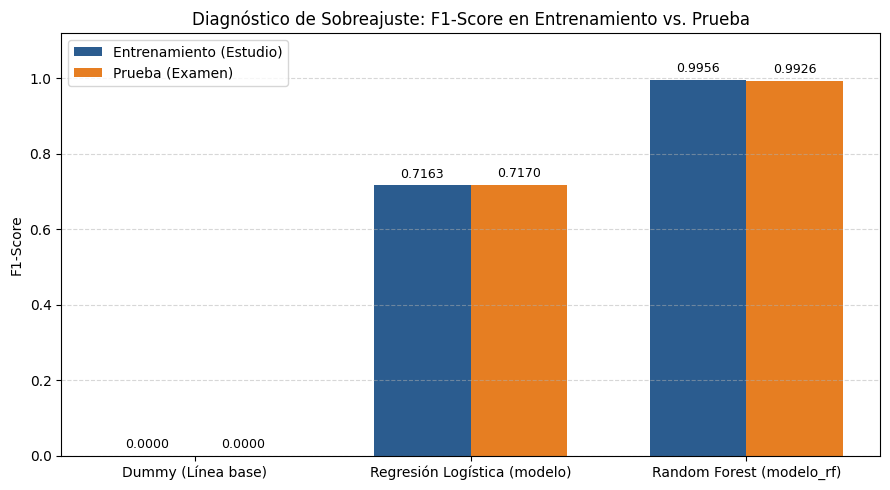

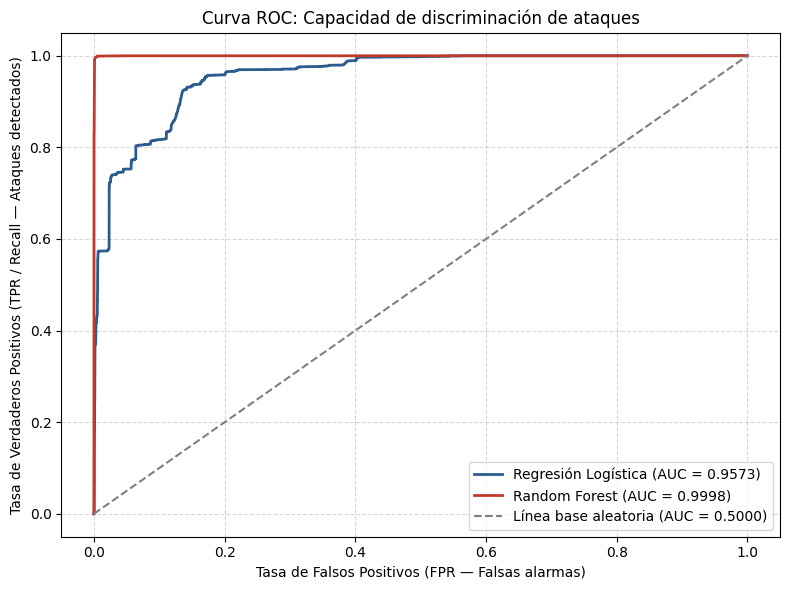

Gráficas guardadas correctamente en: ..\Datos\Analiticos\Resultados


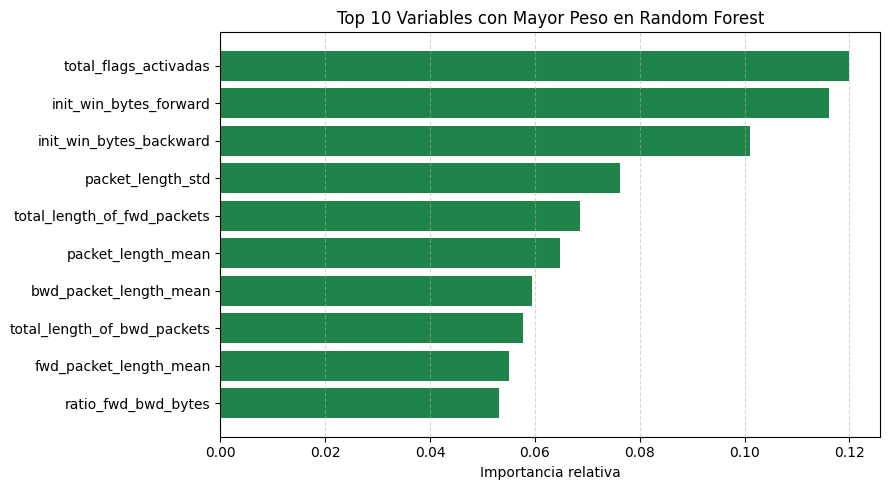

In [12]:
#GRÁFICA: DIAGNÓSTICO DE SOBREAJUSTE

fig, ax = plt.subplots(figsize=(9, 5))

# Posiciones en el eje X para los 3 modelos y ancho de cada barra
x = np.arange(len(df_sobreajuste))
ancho = 0.35

barras_train = ax.bar(x - ancho/2, df_sobreajuste["F1_train (Estudio)"], ancho, label="Entrenamiento (Estudio)", color="#2b5c8f")
barras_test  = ax.bar(x + ancho/2, df_sobreajuste["F1_test (Examen)"], ancho, label="Prueba (Examen)", color="#e67e22")

ax.set_ylabel("F1-Score")
ax.set_title("Diagnóstico de Sobreajuste: F1-Score en Entrenamiento vs. Prueba")
ax.set_xticks(x)
ax.set_xticklabels(df_sobreajuste["Modelo"])
ax.set_ylim(0, 1.12)  # Deja espacio arriba para que quepan los números sin chocar con el borde
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.5)

# Escribir el valor exacto encima de cada barra
for barra in barras_train:
    ax.annotate(f"{barra.get_height():.4f}", (barra.get_x() + barra.get_width()/2, barra.get_height() + 0.02), ha="center", fontsize=9)
for barra in barras_test:
    ax.annotate(f"{barra.get_height():.4f}", (barra.get_x() + barra.get_width()/2, barra.get_height() + 0.02), ha="center", fontsize=9)

plt.tight_layout()
ruta_g1 = MODELOS_ML / "guia09_comparativa_sobreajuste.png"
plt.savefig(ruta_g1, dpi=300)
plt.show()

# GRÁFICA: CURVA COMPARATIVA DE CAPACIDAD DE DISCRIMINACIÓN DE LOS MODELOS 

fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(fpr_lr, tpr_lr, label=f"Regresión Logística (AUC = {metricas['ROC-AUC']:.4f})", color="#2b5c8f", lw=2)
ax.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {metricas_rf['ROC-AUC']:.4f})", color="#c0392b", lw=2)
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Línea base aleatoria (AUC = 0.5000)")

ax.set_xlabel("Tasa de Falsos Positivos (FPR — Falsas alarmas)")
ax.set_ylabel("Tasa de Verdaderos Positivos (TPR / Recall — Ataques detectados)")
ax.set_title("Curva ROC: Capacidad de discriminación de ataques")
ax.legend(loc="lower right")
ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
ruta_g2 = MODELOS_ML / "guia09_curva_de_discriminacion_modelos.png"
plt.savefig(ruta_g2, dpi=300)
plt.show()

print(f"Gráficas guardadas correctamente en: {ANALITICOS_RESULTADOS}")

#GRAFICA : MUESTRA VISUAL DE EL TOP DE 10 VARIABLES DE RANDOM FOREST

top10 = ranking_variables.head(10).iloc[::-1]  # Invertir orden para que la #1 quede arriba
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top10["Variable"], top10["Importancia"], color="#1e8449")
ax.set_xlabel("Importancia relativa")
ax.set_title("Top 10 Variables con Mayor Peso en Random Forest")
ax.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig(MODELOS_ML / "guia09_top_variables_rd.png", dpi=300)
plt.show()


>**Exportacion de modelo candidato**

In [13]:

ruta_modelo_final = MODELOS_ML / "modelo_candidato_guia09.joblib"

joblib.dump(modelo_rf, ruta_modelo_final)

tamano_mb = ruta_modelo_final.stat().st_size / (1024 * 1024)
sha256_modelo = hashlib.sha256(ruta_modelo_final.read_bytes()).hexdigest()[:16]
modelo_recargado = joblib.load(ruta_modelo_final)
pred_prueba = modelo_recargado.predict(X_test.iloc[:5])

print("¡Modelo candidato exportado y verificado con éxito!")
print(f"Ruta de archivo   : {ruta_modelo_final}")
print(f"Tamaño en disco   : {tamano_mb:.2f} MB")
print(f"Huella SHA-256    : {sha256_modelo}")
print(f"Predicción 5 filas: {pred_prueba} (Real: {y_test.iloc[:5].values})")

#Ficha representativa del modelo, como parte de la documentacion de repositorio
ficha_modelo = {
    "modelo_seleccionado": "RandomForestClassifier (Pipeline con preprocesamiento)",
    "archivo_joblib": ruta_modelo_final.name,
    "sha256": sha256_modelo,
    "registros_entrenamiento": int(len(X_train)),
    "columnas_numericas": list(COLS_NUMERICAS),
    "columnas_categoricas": list(COLS_CATEGORICAS),
    "metricas_test": {k: round(float(v), 4) for k, v in metricas_rf.items()}
}
with open(MODELOS_ML / "ficha_modelo_guia09.json", "w", encoding="utf-8") as f:
    json.dump(ficha_modelo, f, indent=4, ensure_ascii=False)


¡Modelo candidato exportado y verificado con éxito!
Ruta de archivo   : ..\Datos\Modelos\modelo_candidato_guia09.joblib
Tamaño en disco   : 17.03 MB
Huella SHA-256    : d85c38d7b87c2c21
Predicción 5 filas: [1 0 0 0 0] (Real: [1 0 0 0 0])


# Conclusión y selección del modelo candidato para hiperparametros

#### Se aplicaron para los 3 modelos esquemas de preprosamiento y particion y como modelo candidato se toma Random Forest por los siguientes criterios estudiados en la guia 8 y 9. 

-> **Mayor calificacion en la implementacion de una línea base**, clasificador Dummy obtuvo un F1-Score:0.0000 al clasificar todo como tráfico normal y no identificar ningun trafico malisioso, el modelo Random Forest mostro un puntaje de detecciones y falsas alarmas del 0.9926 y un puntaje de discrimincacion del 0.9998 en el conjunto de prueba.

-> **Mostro un mayor tolerancia falsas alarmas:** La Regresión Logística logra detectar en puntaje el 0.9571 de los ataques, pero gran parte de sus alertas se mostraron como falsas alarmas con un acierto del 0.5732 en la deteccion real de ataques, el modelo Random Forest detecta en puntaje el 0.9967 de los ataques reales manteniendo un 0.9886 de acierto en cada alerta.

->**No mostro fuga de informacion, ni sobreajuste:** Su rendimiento se mantuvo en el procesamiento con puntaje del 0.9956 y en el comparativa 0.9926 con una desviacion del 0.0030, al momento repetir la prueba en 5 particiones su variación fue aun mas pequeña entre los folds, solamente con puntaje del 0.0007.

->**Facilidad de aplicacion de caracteristicas:** Las características incliudas en el modelo reconocieron el tráfico malicioso con buenos resultados.

->**Conteo de falsos positos:** En el procesamiento de las matrices con conjunto de prueba, la Regresión Logística generó 12,036 falsas alarmas, mientras que Random Forest genero solo 220 registros y logró identificar correctamente 16,683 de los 16,725 ataques reales en el conjunto, mostrando su gran eficiencia en conjuntos mas grandes.